# Airline Review Analysis - Notebook 5: Finding the Topics (POS Tagging and WordNet)

Before I can measure sentiment **per topic** (seat, crew, food, delay...), I need to know what the passengers actually talk about and which words belong to which topic. Instead of guessing the word lists, I use the data:

1. **POS tagging** to find the most common nouns and verbs in the reviews
2. **Adjective + noun pairs** to see what passengers say about each thing
3. **WordNet** to look for synonyms that could extend the topic word lists

Syllabus topics used here (Unit 2): part-of-speech tagging (Penn Treebank tag set), lexical semantics, synonymy, polysemy and word sense ambiguity.

Input: `data/reviews_preprocessed.csv`
Output: `data/topic_words.json` (the topic word lists used in Notebook 6)

## 1. Setup

In [1]:
import re
import json
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet as wn
from nltk.stem import WordNetLemmatizer
from nltk.wsd import lesk

nltk.download("punkt_tab", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 200)
df = pd.read_csv("data/reviews_preprocessed.csv", parse_dates=["review_date"])
lemmatizer = WordNetLemmatizer()
print(df.shape)

(64331, 25)


## 2. Part-of-speech (POS) tagging

POS tagging labels every word with its grammatical role. NLTK uses the Penn Treebank tag set. The tags I need most:

| Tag | Meaning | Example |
|---|---|---|
| NN / NNS | noun (singular / plural) | seat, bags |
| VB, VBD, VBG, VBN | verb forms | cancel, cancelled, boarding |
| JJ | adjective | comfortable |
| RB | adverb | very |
| PRP | pronoun | we |

In [2]:
sentence = "The cabin crew were friendly but the food was cold and our flight was delayed."
pos_tag(word_tokenize(sentence))

[('The', 'DT'),
 ('cabin', 'NN'),
 ('crew', 'NN'),
 ('were', 'VBD'),
 ('friendly', 'RB'),
 ('but', 'CC'),
 ('the', 'DT'),
 ('food', 'NN'),
 ('was', 'VBD'),
 ('cold', 'JJ'),
 ('and', 'CC'),
 ('our', 'PRP$'),
 ('flight', 'NN'),
 ('was', 'VBD'),
 ('delayed', 'VBN'),
 ('.', '.')]

The tagger finds the nouns (crew, food, flight), the adjective "cold" and the verb form "delayed" (VBN). It also makes a small mistake: "friendly" is tagged as an adverb (RB) instead of an adjective. POS taggers are very good but not perfect.

Tagging is slower than the other steps, so I tag a random sample of 10,000 reviews (about 1.3 million words), which is enough to find the common words.

In [3]:
sample = df["review_text"].sample(10000, random_state=1)

tagged_reviews = [pos_tag(word_tokenize(text)) for text in sample]
print("tagged", len(tagged_reviews), "reviews")
print(tagged_reviews[0][:12])

tagged 10000 reviews
[('Five', 'CD'), ('star', 'NN'), ('pricing', 'NN'), ('but', 'CC'), ('two', 'CD'), ('star', 'NN'), ('hospitality', 'NN'), ('.', '.'), ('Once', 'IN'), ('the', 'DT'), ('passengers', 'NNS'), ('boarded', 'VBD')]


## 3. The most common nouns

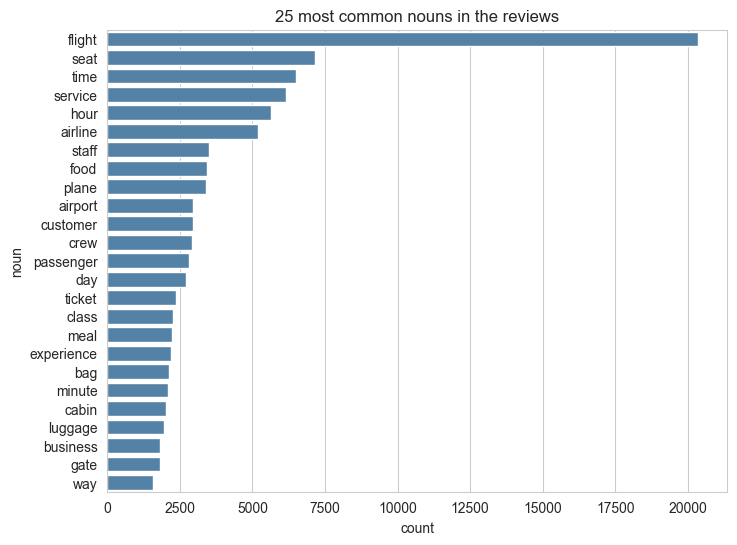

In [4]:
nouns = Counter()
for review in tagged_reviews:
    for word, tag in review:
        word = word.lower()
        if tag in ("NN", "NNS") and word.isalpha() and len(word) > 2:
            nouns[lemmatizer.lemmatize(word, "n")] += 1

top_nouns = pd.DataFrame(nouns.most_common(25), columns=["noun", "count"])

plt.figure(figsize=(8, 6))
sns.barplot(data=top_nouns, x="count", y="noun", color="steelblue")
plt.title("25 most common nouns in the reviews")
plt.show()

Passengers mostly talk about the flight, seat, time, service, hours, staff, food, crew, luggage and so on. Here are the next 60 nouns, which show more specific topics.

In [5]:
more_nouns = [word for word, count in nouns.most_common(85)[25:]]
print(", ".join(more_nouns))

attendant, drink, people, aircraft, economy, trip, delay, entertainment, baggage, lounge, board, leg, problem, check, issue, year, agent, option, hotel, line, return, boarding, choice, nothing, money, departure, refund, thing, system, phone, price, ground, counter, home, water, connection, one, snack, cost, email, lot, room, night, row, number, selection, anything, book, month, movie, desk, company, screen, member, quality, travel, call, point, family, information


Looking at this list I can already see groups of related words:
- **baggage**: bag, luggage, baggage
- **food**: food, meal, drink, snack, breakfast
- **crew**: crew, attendant
- **boarding and check-in**: gate, boarding, check, line
- **money**: refund, money, price, cost
- **delays**: delay, hour, minute
- **entertainment**: entertainment, movie, screen
- **information**: information, email

## 4. The most common verbs

In [6]:
verbs = Counter()
for review in tagged_reviews:
    for word, tag in review:
        word = word.lower()
        if tag.startswith("VB") and word.isalpha() and len(word) > 2:
            verbs[lemmatizer.lemmatize(word, "v")] += 1

common_verbs = {"be", "have", "do", "get", "make", "go", "take", "say", "give", "come", "see", "put", "use", "know", "want", "need", "think", "seem"}
verb_list = [(w, c) for w, c in verbs.most_common(80) if w not in common_verbs][:30]
print(", ".join(w + " (" + str(c) + ")" for w, c in verb_list))

fly (4484), tell (3309), ask (2514), pay (2342), wait (2089), check (1940), arrive (1909), leave (1850), delay (1833), offer (1802), try (1670), find (1647), call (1647), serve (1567), cancel (1508), board (1386), book (1341), provide (1288), miss (1247), travel (1217), change (1195), help (1081), sit (1035), work (1000), receive (984), look (865), keep (853), land (828), connect (819), lose (764)


Many verbs describe problems: **delay**, **cancel**, **wait**, **miss**, **lose**, **pay**. These need to be included, because passengers often say "the flight was delayed" or "they cancelled it" instead of using the nouns.

## 5. What do passengers say about each thing?

Adjectives show the opinion. For each noun I count the adjectives that appear right before it ("comfortable seat") or right after "was / were / is / are" ("the food was terrible").

In [7]:
pairs = Counter()
for review in tagged_reviews:
    for i, (word, tag) in enumerate(review):
        if tag in ("NN", "NNS"):
            noun = lemmatizer.lemmatize(word.lower(), "n")
            # adjective directly before the noun
            if i > 0 and review[i - 1][1].startswith("JJ"):
                pairs[(noun, review[i - 1][0].lower())] += 1
            # noun + was/were/is/are + adjective
            if i + 2 < len(review) and review[i + 1][0].lower() in ("was", "were", "is", "are") and review[i + 2][1].startswith("JJ"):
                pairs[(noun, review[i + 2][0].lower())] += 1

rows = []
for noun in ["seat", "crew", "food", "staff", "service", "baggage", "delay"]:
    adjs = [(adj, c) for (n, adj), c in pairs.most_common() if n == noun][:6]
    rows.append({"noun": noun, "most common adjectives": ", ".join(a + " (" + str(c) + ")" for a, c in adjs)})
pd.DataFrame(rows)

,noun,most common adjectives
0,seat,"comfortable (314), middle (138), window (92), aisle (72), empty (65), good (56)"
1,crew,"friendly (92), cabin (64), nice (43), attentive (41), excellent (40), professional (31)"
2,food,"good (189), excellent (47), great (45), delicious (43), terrible (38), tasty (29)"
3,staff,"cabin (146), friendly (73), rude (67), nice (38), check-in (38), helpful (35)"
4,service,"good (195), excellent (148), poor (85), great (84), terrible (59), full (50)"
5,baggage,"checked (44), excess (26), extra (23), lost (15), check-in (10), free (9)"
6,delay,"slight (19), further (14), long (13), due (12), significant (9), more (8)"


These pairs make sense. Seats are "comfortable" or "middle/window", the crew is "friendly" and "attentive", food is "good", "delicious" or "terrible", and staff are "friendly" or "rude". Baggage is "checked", "extra" or "lost". So adjectives, nouns and verbs together carry the opinion about each topic, which is what I will measure in the next notebook.

## 6. Choosing the topics

From the common nouns and verbs I choose 13 topics that passengers talk about and that matter to an airline. For each topic I write a starting list of words (the "seed words") that I found in the lists above. Words are written in their **lemma form** (delayed becomes delay), and a topic can also have short phrases.

Some frequent words are left out on purpose because they are too general or ambiguous. For example "staff" could mean cabin staff or ground staff, so I only use it inside phrases such as "ground staff" and "cabin staff". Words like "lounge", "airport" and "hotel" are also left out to keep the project manageable.

In [8]:
seed_words = {
    "delay": {"words": ["delay", "postpone", "reschedule", "punctual"],
              "phrases": ["be late", "arrive late", "run late", "depart late", "hour late", "hour delay",
                          "on time", "wait hour", "wait for hour"]},
    "cancellation": {"words": ["cancel", "cancellation"], "phrases": []},
    "baggage": {"words": ["bag", "baggage", "luggage", "suitcase"], "phrases": ["carry on"]},
    "boarding_checkin": {"words": ["board", "gate", "queue", "security", "immigration"], "phrases": ["check in"]},
    "cabin_crew": {"words": ["crew", "attendant", "steward", "stewardess", "purser", "hostess"],
                   "phrases": ["cabin staff", "cabin service", "flight attendant"]},
    "ground_staff": {"words": ["agent", "counter", "desk"],
                     "phrases": ["ground staff", "ground crew", "ground service", "airport staff", "gate agent",
                                 "check in staff", "customer service", "customer care", "customer support",
                                 "call center", "call centre", "service desk"]},
    "seat": {"words": ["seat", "legroom", "recline", "cramp"], "phrases": ["leg room", "lie flat"]},
    "food": {"words": ["food", "meal", "snack", "drink", "breakfast", "lunch", "dinner", "catering", "wine", "coffee"],
             "phrases": []},
    "entertainment": {"words": ["entertainment", "ife", "screen", "movie", "headphone"], "phrases": []},
    "wifi": {"words": ["wifi", "internet", "connectivity"], "phrases": ["wi fi"]},
    "value_fees": {"words": ["price", "fare", "cost", "fee", "expensive", "cheap", "overpriced", "charge", "worth",
                             "value", "money"], "phrases": []},
    "refund_compensation": {"words": ["refund", "compensation", "compensate", "reimburse", "reimbursement", "voucher"],
                            "phrases": ["money back", "travel credit"]},
    "communication": {"words": ["communicate", "communication", "inform", "information", "update", "announce",
                                "announcement", "notify", "notification", "explanation", "explain"], "phrases": []},
}
print(len(seed_words), "topics")

13 topics


## 7. WordNet: can it find more words for each topic?

WordNet is a dictionary where words are grouped into sets of synonyms (synsets). It also lists all the different meanings (senses) of a word. First let me look at the senses of two words from my topics.

In [9]:
for word in ["seat", "board"]:
    print(word.upper())
    for synset in wn.synsets(word, pos=wn.NOUN)[:5]:
        print("  ", synset.name(), "-", synset.definition())
    print()

SEAT
   seat.n.01 - a space reserved for sitting (as in a theater or on a train or airplane)
   buttocks.n.01 - the fleshy part of the human body that you sit on
   seat.n.03 - furniture that is designed for sitting on
   seat.n.04 - any support where you can sit (especially the part of a chair or bench etc. on which you sit)
   seat.n.05 - a center of authority (as a city from which authority is exercised)

BOARD
   board.n.01 - a committee having supervisory powers
   board.n.02 - a stout length of sawn timber; made in a wide variety of sizes and used for many purposes
   board.n.03 - a flat piece of material designed for a special purpose
   board.n.04 - food or meals in general
   display_panel.n.01 - a vertical surface on which information can be displayed to public view



A word has many senses: "seat" can be a chair, a position in parliament or the buttocks, and "board" can be a plank or a group of directors. This is **polysemy** (one word with several meanings), and it is why word sense ambiguity is a challenge in NLP.

NLTK has the Lesk algorithm, a dictionary-based method that tries to choose the right sense by comparing the sentence with the definitions. Let me test it.

In [10]:
sentences = ["We had to board the plane at gate twelve",
             "The board of directors approved the new budget",
             "I booked a window seat near the front"]
words = ["board", "board", "seat"]

for text, word in zip(sentences, words):
    sense = lesk(word_tokenize(text), word, "n")
    print(word, "->", sense, "-", sense.definition() if sense else None)

board -> Synset('circuit_board.n.01') - a printed circuit that can be inserted into expansion slots in a computer to increase the computer's capabilities
board -> Synset('board.n.02') - a stout length of sawn timber; made in a wide variety of sizes and used for many purposes
seat -> Synset('seat.n.04') - any support where you can sit (especially the part of a chair or bench etc. on which you sit)


Lesk does not always choose the right sense (it can be wrong even for these simple sentences). So I do not use word sense disambiguation in this project. The topic is decided from the word together with the data (nouns, verbs and phrases that are common in reviews).

Now I ask WordNet for synonyms of my seed words and keep only the ones that really appear in the reviews (at least 15 times).

In [11]:
vocab = Counter()
for review in tagged_reviews:
    for word, tag in review:
        word = word.lower()
        if word.isalpha() and len(word) > 2:
            vocab[lemmatizer.lemmatize(word, "n")] += 1

already_used = {w for t in seed_words.values() for w in t["words"]}

suggestions = []
for topic, entry in seed_words.items():
    found = {}
    for seed in entry["words"]:
        for synset in wn.synsets(seed, pos=wn.NOUN)[:3]:
            for lemma in synset.lemma_names():
                lemma = lemma.lower()
                if "_" not in lemma and lemma not in already_used and vocab.get(lemma, 0) >= 15:
                    found[lemma] = vocab[lemma]
    if found:
        suggestions.append({"topic": topic, "WordNet suggestions (count in reviews)": ", ".join(w + " (" + str(c) + ")" for w, c in sorted(found.items(), key=lambda x: -x[1]))})
pd.DataFrame(suggestions)

,topic,WordNet suggestions (count in reviews)
0,delay,"wait (1101), hold (344)"
1,baggage,base (18)
2,cabin_crew,"bunch (25), crowd (24)"
3,seat,"can (2400), place (338), behind (283), rear (65), bottom (58), tail (22)"
4,food,"beverage (348), bite (20)"
5,entertainment,"phone (865), film (161), picture (62), earphone (32), blind (18)"
6,value_fees,"complaint (422), menu (321), damage (62), transportation (62)"
7,refund_compensation,coupon (29)
8,communication,"telling (190), notice (174), account (119), info (94)"


Most of the suggestions are wrong for airline reviews because WordNet mixes all senses of a word: for "seat" it suggests "can", "place", "behind" and "rear", for "screen" it suggests "phone", for "price" and "cost" it suggests "complaint", "menu" and "damage", and for "delay" it suggests "wait" and "hold", which are too general. A few suggestions are useful: **beverage** (food), **film** (entertainment), **info** (communication) and **coupon** (refund).

I keep only the useful ones. This shows that WordNet is helpful, but its suggestions have to be checked.

In [12]:
wordnet_additions = {
    "food": ["beverage"],
    "entertainment": ["film"],
    "communication": ["info"],
    "refund_compensation": ["coupon"],
}

topic_words = {}
for topic, entry in seed_words.items():
    words = entry["words"] + wordnet_additions.get(topic, [])
    topic_words[topic] = {"words": words, "phrases": entry["phrases"]}

for topic, entry in topic_words.items():
    print(topic, "->", len(entry["words"]), "words,", len(entry["phrases"]), "phrases")

delay -> 4 words, 9 phrases
cancellation -> 2 words, 0 phrases
baggage -> 4 words, 1 phrases
boarding_checkin -> 5 words, 1 phrases
cabin_crew -> 6 words, 3 phrases
ground_staff -> 3 words, 12 phrases
seat -> 4 words, 2 phrases
food -> 11 words, 0 phrases
entertainment -> 6 words, 0 phrases
wifi -> 3 words, 1 phrases
value_fees -> 11 words, 0 phrases
refund_compensation -> 7 words, 2 phrases
communication -> 12 words, 0 phrases


## 8. Testing the word lists

I write a function that finds the topics mentioned in a text. It uses the same preprocessing as before (lowercase, regex, lemmatization) but **keeps the stopwords**, so that phrases like "check in" stay intact.

In [13]:
lemma_cache = {}
keep_as_is = {"ground"}

def get_lemma(word):
    if word in keep_as_is:
        return word
    if word not in lemma_cache:
        lemma = lemmatizer.lemmatize(word, pos="v")
        lemma_cache[word] = lemmatizer.lemmatize(lemma, pos="n")
    return lemma_cache[word]


def expand_contractions(text):
    text = text.replace("’", "'")
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "can not", text)
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"\b(did|does|do|was|were|is|are|would|could|should|have|has|had|can)nt\b", r"\1 not", text)
    return text


def to_lemmas(text):
    text = expand_contractions(text.lower())
    text = text.replace("on board", "onboard")      # 'on board service' is not about boarding
    text = re.sub(r"[^a-z\s]", " ", text)
    return [get_lemma(w) for w in text.split()]


def find_topics(text):
    lemmas = to_lemmas(text)
    lemma_set = set(lemmas)
    joined = " " + " ".join(lemmas) + " "
    found = []
    for topic, entry in topic_words.items():
        if any(w in lemma_set for w in entry["words"]) or any(" " + p + " " in joined for p in entry["phrases"]):
            found.append(topic)
    return found


print(find_topics("The flight was delayed for hours and nobody gave us any information."))
print(find_topics("Cabin crew were lovely, the seats were comfortable and the food was tasty."))
print(find_topics("They lost my luggage and refused to give a refund."))

['delay', 'communication']
['cabin_crew', 'seat', 'food']
['baggage', 'refund_compensation']


The function finds the right topics in these three examples. Now I check how many of the 10,000 sample reviews mention each topic.

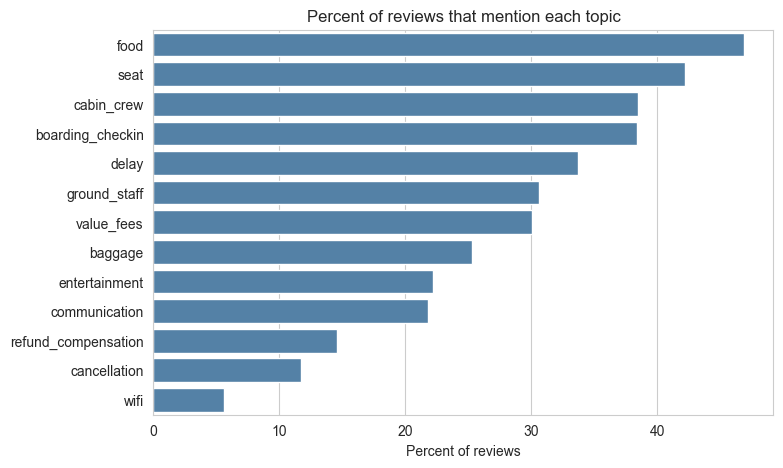

reviews with at least one topic: 97.0 %
average topics per review: 3.6


In [14]:
sample_topics = sample.apply(find_topics)

coverage = pd.Series({t: sample_topics.apply(lambda found: t in found).mean() * 100 for t in topic_words})
coverage = coverage.sort_values(ascending=False).round(1)

plt.figure(figsize=(8, 5))
sns.barplot(x=coverage.values, y=coverage.index, color="steelblue")
plt.title("Percent of reviews that mention each topic")
plt.ylabel("")
plt.xlabel("Percent of reviews")
plt.show()

print("reviews with at least one topic:", round((sample_topics.str.len() > 0).mean() * 100, 1), "%")
print("average topics per review:", round(sample_topics.str.len().mean(), 1))

The most mentioned topics are food (about 47% of reviews), seat (42%), cabin crew and boarding / check-in (about 38% each) and delay (34%). Refund, cancellation and WiFi are mentioned in fewer reviews (about 15%, 12% and 6%). Almost every review (97%) mentions at least one topic, and an average review mentions 3.6 topics, so the word lists cover the data well.

This only shows that a topic word appears in a review, not whether the passenger is happy or unhappy about it. That is the next step. Whether the word lists pick the right sentences will be tested in Notebook 7, using the dataset's own ratings.

## 9. Saving the topic word lists

In [15]:
with open("data/topic_words.json", "w") as f:
    json.dump(topic_words, f, indent=2)
print("saved data/topic_words.json")

saved data/topic_words.json


## Summary

- POS tagging was used to find the most common nouns and verbs in the reviews, and to see which adjectives go with which noun.
- From these I chose 13 topics: delay, cancellation, baggage, boarding and check-in, cabin crew, ground staff, seat, food, entertainment, WiFi, value and fees, refund and compensation, and communication.
- WordNet showed word sense ambiguity clearly: most synonym suggestions were wrong for this domain, and only four were useful. The Lesk algorithm was not reliable either.
- The word lists are saved in `data/topic_words.json` and `find_topics()` is tested on the reviews.

Next notebook: aspect based sentiment analysis, which splits reviews into sentences, finds the topic of each sentence and measures the sentiment of each topic.